<a href="https://www.kaggle.com/code/gilmanmuslih/fainel-projek-pil?scriptVersionId=367292060" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# POI Retrieval: baseline teks di Yelp

**Cara pakai:** jalanin cell dari atas ke bawah, satu per satu. Hanya cell bertanda **✏️ EDIT** yang perlu lu ubah.
Semua skrip dan snippet lama dari chat boleh diabaikan, semuanya sudah ada di notebook ini.

| Langkah | Cell | Pakai GPU? |
|---|---|---|
| 0. Setup + tulis skrip | 1-2 | tidak |
| 1. Pilih metro/state | 3-4 | tidak |
| 2. Tulis query | 5-6 | tidak |
| 3. Baseline BM25 | 7-8 | tidak |
| 4. Baseline dense | 9 | ya (nyalain GPU hanya di sini) |

## Langkah 0: Setup

In [1]:
!mkdir poi-retrieval

In [2]:
cd poi-retrieval

/kaggle/working/poi-retrieval


In [3]:
!pip install -q rank_bm25 sentence-transformers

Cell ini menulis skrip baseline ke disk (versi terbaru). **Jangan diedit.**

In [4]:
%%writefile /kaggle/working/poi-retrieval/baseline_text.py
#!/usr/bin/env python3
"""
Baseline teks untuk POI retrieval di Yelp: BM25, dense (embedding review), dan RRF hybrid.
Output: top-k per query per metode, plus "pool" gabungan untuk annotator.

Persiapan (Kaggle: GPU T4 hanya perlu untuk dense; BM25 jalan di CPU):
    pip install rank_bm25 sentence-transformers pandas

File query (CSV), kolom wajib id,text ; kolom type opsional:
    id,text,type
    P1,"I want to relax while camping near a river with shady forest",mixed
    ...

Contoh:
    python baseline_text.py \
        --business /kaggle/input/.../yelp_academic_dataset_business.json \
        --reviews  /kaggle/input/.../yelp_academic_dataset_review.json \
        --cats "Parks,Campgrounds,Beaches" --city Boise --state ID \
        --queries queries.csv --outdir out_text

    Multi-metro: --state IN,FL,LA (beberapa state sekaligus; satu state Yelp ~ satu metro).
    Tambahkan kolom `state` di queries.csv (mis. TN) supaya tiap query hanya mencari di metronya.
    Tanpa --cats = korpus satu kota penuh (semua kategori), lebih realistis untuk query bebas.
    --dense none           lewati dense (BM25 saja, tanpa GPU)
    --review-cache f.jsonl simpan subset review supaya run berikutnya tidak baca 5 GB lagi

Catatan desain:
- BM25 bekerja di level POI (nama + kategori + gabungan review).
- Dense meng-embed tiap review, lalu skor POI = max (atau top-3 mean) kemiripan antar review POI itu.
  Ini keputusan "pooling" yang bisa lu jadikan baris ablasi.
- Atribut Yelp (Ambience, NoiseLevel, dst.) SENGAJA tidak dipakai di sini, supaya bisa
  dipakai sebagai ground truth otomatis nanti.
"""
import argparse
import os
import re
import sys

import numpy as np
import pandas as pd

STOP = set("""a an and are as at be but by for from has have i if in into is it its me my of on or
so that the their them then there these they this to was we were what when where which who will with
would you your want like looking find place places near nice good great""".split())

E5_INSTRUCT = "Instruct: Given a search query, retrieve business reviews that match the query\nQuery: "


def read_jsonl(path, **kw):
    return pd.read_json(path, lines=True, dtype=False, convert_dates=False, **kw)


def tokenize(s):
    return [t for t in re.findall(r"[a-z0-9]+", str(s).lower()) if t not in STOP and len(t) > 1]


# ---------- data ----------
def select_pois(business_path, cats, city, state, min_reviews):
    df = read_jsonl(business_path)
    df["categories"] = df["categories"].fillna("")
    df["review_count"] = pd.to_numeric(df["review_count"], errors="coerce").fillna(0).astype(int)
    wanted = {c.strip().lower() for c in cats if c.strip()}
    if wanted:  # tanpa --cats: semua kategori (korpus satu kota penuh)
        df = df[df["categories"].map(lambda s: any(c.strip().lower() in wanted for c in s.split(",")))]
    if city:
        df = df[df["city"].str.lower() == city.lower()]
    if state:  # boleh beberapa state dipisah koma, mis. "IN,FL,LA"
        states = {x.strip().lower() for x in state.split(",") if x.strip()}
        df = df[df["state"].str.lower().isin(states)]
    df = df[df["review_count"] >= min_reviews].reset_index(drop=True)
    return df[["business_id", "name", "city", "state", "categories", "review_count",
               "latitude", "longitude"]]


def load_reviews(reviews_path, ids, cache):
    if cache and os.path.exists(cache):
        cached = read_jsonl(cache)
        cached = cached[cached["business_id"].isin(ids)]
        covered = cached["business_id"].nunique() / max(len(ids), 1)
        if covered >= 0.8:  # cache cukup mewakili POI yang diminta
            print(f"Pakai cache review: {cache} (mencakup {covered:.0%} POI)")
            return cached.reset_index(drop=True)
        print(f"Cache {cache} hanya mencakup {covered:.0%} POI yang diminta "
              f"(kemungkinan dibuat untuk scope lain). Baca ulang review.json dan timpa cache.")
    parts = []
    for ch in read_jsonl(reviews_path, chunksize=200_000):
        ch = ch[ch["business_id"].isin(ids)][["business_id", "review_id", "text"]]
        if len(ch):
            parts.append(ch)
    rv = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(
        columns=["business_id", "review_id", "text"])
    if cache:
        rv.to_json(cache, orient="records", lines=True, force_ascii=False)
    return rv


def cap_reviews(rv, n, seed=0):
    if n <= 0:
        return rv
    rv = rv.sample(frac=1.0, random_state=seed)
    return rv.groupby("business_id", sort=False).head(n).reset_index(drop=True)


# ---------- BM25 ----------
def bm25_scores(pois, rv, queries):
    from rank_bm25 import BM25Okapi
    by_poi = rv.groupby("business_id")["text"].apply(lambda s: " ".join(s)).to_dict()
    docs = []
    for _, r in pois.iterrows():
        txt = f'{r["name"]} {r["categories"]} {by_poi.get(r["business_id"], "")}'
        docs.append(tokenize(txt))
    bm = BM25Okapi(docs)
    return np.vstack([bm.get_scores(tokenize(q)) for q in queries])  # [n_query, n_poi]


# ---------- dense ----------
def load_encoder(name):
    from sentence_transformers import SentenceTransformer
    import torch
    model = SentenceTransformer(name, device="cuda" if torch.cuda.is_available() else "cpu")
    if torch.cuda.is_available():
        model.half()  # T4: fp16, bukan bf16
    model.max_seq_length = 256

    def enc(texts, is_query=False):
        if is_query and "e5" in name.lower() and "instruct" in name.lower():
            texts = [E5_INSTRUCT + t for t in texts]
        elif "e5" in name.lower() and "instruct" not in name.lower():
            texts = [("query: " if is_query else "passage: ") + t for t in texts]
        return model.encode(texts, batch_size=64, normalize_embeddings=True,
                            show_progress_bar=not is_query)
    return enc


def dense_scores(enc, pois, rv, queries, pool="max", emb_cache=None):
    pid = {b: i for i, b in enumerate(pois["business_id"])}
    rv = rv[rv["business_id"].isin(pid)].copy()
    rv["pi"] = rv["business_id"].map(pid)
    rv = rv.sort_values("pi").reset_index(drop=True)

    import hashlib
    fp = hashlib.md5("|".join(rv["review_id"].astype(str)).encode()).hexdigest()
    fp_path = (emb_cache + ".fp") if emb_cache else None
    R = None
    if emb_cache and os.path.exists(emb_cache) and os.path.exists(fp_path):
        if open(fp_path).read().strip() == fp:
            R = np.load(emb_cache)
            print(f"Pakai cache embedding: {emb_cache}")
        else:
            print("Cache embedding dibuat untuk set review yang berbeda -> hitung ulang.")
    if R is None:
        R = np.asarray(enc(rv["text"].tolist(), is_query=False), dtype=np.float32)
        if emb_cache:
            np.save(emb_cache, R)
            open(fp_path, "w").write(fp)
    Q = np.asarray(enc(list(queries), is_query=True), dtype=np.float32)
    sims = Q @ R.T                                   # [n_query, n_review]
    pi = rv["pi"].to_numpy()
    n_poi = len(pois)
    out = np.full((len(queries), n_poi), -1.0, dtype=np.float32)
    starts = np.r_[0, np.flatnonzero(np.diff(pi)) + 1]
    owners = pi[starts]
    if pool == "max":
        out[:, owners] = np.maximum.reduceat(sims, starts, axis=1)
    else:  # top3 mean
        ends = np.r_[starts[1:], len(pi)]
        for k, (s, e) in enumerate(zip(starts, ends)):
            seg = np.sort(sims[:, s:e], axis=1)[:, ::-1][:, :3]
            out[:, owners[k]] = seg.mean(axis=1)
    return out


# ---------- filter metro/state per query ----------
def metro_mask(qdf, pois):
    """Boolean [n_query, n_poi]. Kolom 'state' di queries.csv (mis. TN) membatasi kandidat
    ke state itu; kosong atau 'ALL' = tanpa batas. Semua baseline dapat filter yang SAMA."""
    n_q, n_p = len(qdf), len(pois)
    if "state" not in qdf.columns:
        return np.ones((n_q, n_p), dtype=bool)
    ps = pois["state"].str.lower().to_numpy()
    mask = np.ones((n_q, n_p), dtype=bool)
    for i, v in enumerate(qdf["state"].fillna("").astype(str)):
        v = v.strip().lower()
        if v and v != "all":
            mask[i] = ps == v
    return mask


def apply_mask(S, mask, fill=-1e9):
    return np.where(mask, S, fill)


# ---------- fusi & output ----------
def rrf(score_mats, k=60):
    fused = np.zeros_like(score_mats[0], dtype=np.float64)
    for S in score_mats:
        ranks = (-S).argsort(axis=1).argsort(axis=1) + 1
        fused += 1.0 / (k + ranks)
    return fused


def topk_rows(qids, pois, S, method, k, mask=None):
    rows = []
    for qi, qid in enumerate(qids):
        order = np.argsort(-S[qi])
        if mask is not None:  # buang POI di luar metro query, jangan jadi pengisi top-k
            order = order[mask[qi][order]]
        idx = order[:k]
        for r, j in enumerate(idx, 1):
            rows.append({"query_id": qid, "method": method, "rank": r,
                         "business_id": pois.iloc[j]["business_id"],
                         "name": pois.iloc[j]["name"], "score": float(S[qi, j])})
    return rows


def build_pool(runs, qdf, pois, pool_k):
    p = runs[runs["rank"] <= pool_k]
    g = p.groupby(["query_id", "business_id"]).agg(
        methods=("method", lambda s: "|".join(sorted(set(s)))),
        best_rank=("rank", "min")).reset_index()
    g = g.merge(qdf[["id", "text"]].rename(columns={"id": "query_id", "text": "query"}), on="query_id")
    g = g.merge(pois[["business_id", "name", "city", "state", "categories"]], on="business_id")
    for c in ("label_a1", "label_a2", "label_a3"):
        g[c] = ""
    return g.sort_values(["query_id", "best_rank"])[
        ["query_id", "query", "business_id", "name", "city", "state", "categories",
         "methods", "best_rank", "label_a1", "label_a2", "label_a3"]]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--business", required=True)
    ap.add_argument("--reviews", help="review.json (atau file cache dari --review-cache)")
    ap.add_argument("--cats", default="",
                    help="filter kategori (pisah koma). Kosongkan = semua kategori di kota itu")
    ap.add_argument("--city", nargs="+", help="nama kota; boleh lebih dari satu kata, mis. --city New Orleans")
    ap.add_argument("--state")
    ap.add_argument("--min-reviews", type=int, default=10)
    ap.add_argument("--max-reviews-per-poi", type=int, default=100)
    ap.add_argument("--queries", required=True)
    ap.add_argument("--dense", default="intfloat/multilingual-e5-large-instruct",
                    help="nama model sentence-transformers, atau 'none'")
    ap.add_argument("--pool", choices=["max", "top3"], default="max")
    ap.add_argument("--topk", type=int, default=20)
    ap.add_argument("--pool-k", type=int, default=10)
    ap.add_argument("--review-cache")
    ap.add_argument("--outdir", default="out_text")
    args = ap.parse_args()
    args.city = " ".join(args.city) if args.city else None
    os.makedirs(args.outdir, exist_ok=True)

    cats = [c.strip() for c in args.cats.split(",") if c.strip()]
    pois = select_pois(args.business, cats, args.city, args.state, args.min_reviews)
    if pois.empty:
        sys.exit("Tidak ada POI yang cocok. Cek --cats/--city/--state.")
    print(f"POI terpilih: {len(pois)}")

    rv = load_reviews(args.reviews, set(pois["business_id"]), args.review_cache)
    rv = cap_reviews(rv, args.max_reviews_per_poi)
    print(f"Review dipakai: {len(rv)} (maks {args.max_reviews_per_poi} per POI)")

    qdf = pd.read_csv(args.queries)
    qids, qtexts = qdf["id"].tolist(), qdf["text"].tolist()

    mask = metro_mask(qdf, pois)
    mats = {"bm25": apply_mask(bm25_scores(pois, rv, qtexts), mask)}
    if args.dense.lower() != "none":
        enc = load_encoder(args.dense)
        emb_cache = os.path.join(args.outdir, "review_emb.npy")
        mats["dense"] = apply_mask(
            dense_scores(enc, pois, rv, qtexts, pool=args.pool, emb_cache=emb_cache), mask)
        mats["rrf"] = rrf([mats["bm25"], mats["dense"]])

    rows = []
    for name, S in mats.items():
        rows += topk_rows(qids, pois, S, name, args.topk, mask)
    runs = pd.DataFrame(rows)
    runs.to_csv(os.path.join(args.outdir, "runs_text.csv"), index=False)
    pool = build_pool(runs, qdf, pois, args.pool_k)
    pool.to_csv(os.path.join(args.outdir, "pool_for_annotation.csv"), index=False)

    print(f"\nTersimpan di {args.outdir}/")
    print(f"  runs_text.csv            : top-{args.topk} per query per metode")
    print(f"  pool_for_annotation.csv  : {len(pool)} pasangan unik (top-{args.pool_k} gabungan)")


if __name__ == "__main__":
    main()

Writing /kaggle/working/poi-retrieval/baseline_text.py


## Langkah 1: Pilih metro/state

**✏️ EDIT** `DATA` kalau path dataset lu beda. `STATES` diisi setelah lihat tabel di cell berikutnya.

In [5]:
import os, pandas as pd

DATA = "/kaggle/input/datasets/gilmanmuslih/datasetyelppjson"   # ✏️ folder yang berisi file json Yelp
WORK = "/kaggle/working/poi-retrieval"
MIN_REVIEWS = 10            # ✏️ POI dengan review kurang dari ini dibuang
MAX_REV_PER_POI = 15        # ✏️ turunin kalau embedding kelamaan
STATES = "IN,PA,FL"               # ✏️ isi setelah lihat tabel di bawah, mis. "IN,FL,LA"
DENSE_MODEL = "intfloat/multilingual-e5-base"   # ✏️ lebih kuat tapi lebih berat: intfloat/multilingual-e5-large-instruct

print(os.listdir(DATA))

['Dataset_User_Agreement.pdf', 'yelp_academic_dataset_business.json', 'yelp_academic_dataset_checkin.json', 'yelp_academic_dataset_review.json', 'yelp_academic_dataset_tip.json', 'yelp_academic_dataset_user.json']


In [6]:
# Hitung jumlah POI total dan POI outdoor per state (CPU, beberapa menit)
df = pd.read_json(f"{DATA}/yelp_academic_dataset_business.json", lines=True, dtype=False)
df["categories"] = df["categories"].fillna("")
df["review_count"] = pd.to_numeric(df["review_count"], errors="coerce").fillna(0).astype(int)

PAT = r"\b(?:park|parks|camp|campground|campgrounds|beach|beaches|hiking|lake|lakes|river|rivers|garden|gardens|trail|trails|nature|zoo|zoos|playground|playgrounds)\b"
ok = df[df["review_count"] >= MIN_REVIEWS]
out = ok[ok["categories"].str.contains(PAT, case=False, regex=True)]
tbl = pd.DataFrame({"poi_total": ok.groupby("state").size(),
                    "poi_outdoor": out.groupby("state").size()}).fillna(0).astype(int)
print(tbl.sort_values("poi_total", ascending=False).head(15))
print("\nPilih 3-4 state dengan poi_outdoor besar dan karakter berbeda, lalu isi STATES di cell sebelumnya.")

       poi_total  poi_outdoor
state                        
PA         22679          867
FL         17080          833
TN          8209          369
IN          7522          381
MO          7268          348
LA          6925          253
AZ          6628          368
NV          5373          312
NJ          5265          208
CA          3784          230
AB          2972          108
ID          2856          137
DE          1455           68
IL          1215           55
HI             2            0

Pilih 3-4 state dengan poi_outdoor besar dan karakter berbeda, lalu isi STATES di cell sebelumnya.


## Langkah 2: Tulis query

Cell pertama menampilkan POI outdoor di state terpilih (bahan nulis query). Cell kedua **✏️ EDIT**: ganti query contoh dengan 25-30 query lu.

In [7]:
# Re-run cell ini setelah STATES diubah
want = [s.strip() for s in STATES.split(",")]
sel = out[out["state"].isin(want)]
print("POI outdoor di", want, ":", len(sel))
print(sel.sort_values("review_count", ascending=False)[["name","city","state","categories","review_count"]].head(60).to_string())

POI outdoor di ['IN', 'PA', 'FL'] : 2081
                                              name              city state                                                                                                                                                                                                                         categories  review_count
17663                            John's Roast Pork      Philadelphia    PA                                                                                                     Sandwiches, Salad, American (Traditional), Cheesesteaks, Breakfast & Brunch, Active Life, American (New), Beaches, Restaurants          1564
111226                     Busch Gardens Tampa Bay             Tampa    FL                                                                                                                                                              Active Life, Amusement Parks, Botanical Gardens, Arts & Entertainment          1325
6776       

In [8]:
%%writefile /kaggle/working/poi-retrieval/queries.csv
id,text,type,state,persona,anchor_hint
A01,somewhere I can kayak through mangroves and maybe spot dolphins,activity,FL,tourist,Fort De Soto Park
A02,a place where my dog can swim off leash in the water,activity,FL,dog owner,Honeymoon Island State Park; Fort De Soto Park
A03,where can we lie in a hammock by the water on a summer evening,activity,PA,couple,Spruce Street Harbor Park
A04,a place to pick our own apples and let the kids feed farm animals,activity,PA,family,Linvilla Orchards; Shady Brook Farm
A05,somewhere quiet to sit on a shaded bench and read outdoors,activity,IN,solo reader,Holliday Park; Newfields
A06,a place to fish off a dock or rent a small boat for the afternoon,activity,FL,angler,Hubbard's Marina; Fort De Soto Park
A07,a good place to go birdwatching early in the morning,activity,IN,birdwatcher,Marott Park; Eagle Creek Park (cek)
A08,a garden where I can photograph flowers in full bloom,activity,PA,photographer,Longwood Gardens
A09,a park where a big group can picnic and use a shelter with grills,activity,IN,group,Fort Harrison State Park; Westside Park
P01,"a park with a creek, small bridges and old stone ruins",physical,IN,explorer,Holliday Park
P02,a boardwalk through a swamp with cypress trees and wildlife,physical,FL,hiker,Lettuce Lake Park (cek)
P03,a wooded trail that follows a river with a few steep hills,physical,IN,hiker,Marott Park; Fort Harrison State Park
P04,an indoor conservatory full of tropical plants and fountains,physical,PA,tourist,Longwood Gardens
P05,a restaurant with tables right on the sand,physical,FL,diner,Sunset Grill at Little Harbor; Hogan's Beach
P06,a big reservoir with a marina and miles of hiking trails,physical,IN,hiker,Eagle Creek Park (cek)
P07,a historic fort by the water with cannons you can walk around,physical,FL,history fan,Fort De Soto Park
P08,a cafe with a large garden courtyard and outdoor seating,physical,PA,brunch fan,Suraya; Front Street Cafe
P09,a rooftop deck overlooking the gulf,physical,FL,friends,Hurricane Seafood Restaurant
F01,a peaceful hidden spot to escape the city noise for a while,affective,PA,office worker,Longwood Gardens; Wissahickon Valley Park (cek)
F02,"a laid-back, no-frills beach bar where locals actually hang out",affective,FL,local,Hurricane Seafood Restaurant; The Honu
F03,"a cozy, relaxing place that feels like being out in the countryside",affective,IN,couple,
F04,a romantic spot for a slow evening stroll,affective,PA,couple,Spruce Street Harbor Park; Rittenhouse Square Park
F05,a calm place to clear my head and be alone with nature,affective,IN,solo,Marott Park; Fort Harrison State Park
F06,"a lively, buzzing outdoor spot with a fun crowd on weekend nights",affective,PA,friends,Frankford Hall; Independence Beer Garden
F07,a charming old-Florida kind of place that doesn't feel touristy,affective,FL,tourist,
F08,"a serene, beautiful place to unwind on a Sunday morning",affective,PA,solo,Longwood Gardens
F09,an uncrowded park that feels safe for a solo walk,affective,IN,solo,
M01,a quiet dog-friendly bar or cafe with outdoor seating and a breeze,mixed,FL,dog owner,The Honu
M02,a relaxed beer garden with shade trees and room for kids to run around,mixed,PA,parent,Independence Beer Garden; Frankford Hall
M03,a peaceful wooded park with clean restrooms and paved paths for a stroller,mixed,IN,parent,
M04,a romantic seafood dinner with a water view that isn't too pricey,mixed,FL,couple,Sunset Grill at Little Harbor; Hogan's Beach
M05,"a calm, leafy patio cafe where I can work on my laptop for a few hours",mixed,PA,remote worker,Front Street Cafe; Terrain At Styers
M06,"a scenic, not-too-crowded trail along the water that is easy on the knees",mixed,IN,older adult,
M07,"a family beach with shade, picnic tables and gentle waves for toddlers",mixed,FL,parent,Fort De Soto Park
M08,a quiet nature preserve with wildflowers and no bikes on the trails,mixed,IN,hiker,Marott Park
M09,an uncrowded natural beach where we can bring a cooler and stay all day,mixed,FL,beachgoer,Fort De Soto Park; Honeymoon Island State Park
S01,good place for a nature walk before hitting the beach,spatial,FL,tourist,Fort De Soto Park; Honeymoon Island State Park
S02,a casual lunch spot within walking distance of the beach,spatial,FL,beachgoer,Clearwater Beach area (cek)
S03,a cafe right by a big park where I can grab coffee before a long walk,spatial,PA,walker,
S04,a trail that ends near a brewery so we can grab a beer after hiking,spatial,IN,hiker,
S05,a seafood restaurant next to the marina where we can watch the boats,spatial,FL,diner,Hubbard's Marina area (cek)
S06,somewhere to eat outside close to the river trail after a bike ride,spatial,PA,cyclist,
S07,a quiet park on the water just across from the busy downtown,spatial,FL,local,The Tampa Riverwalk area (cek)
S08,a playground right next to a creek or pond where kids can explore,spatial,IN,parent,Holliday Park
S09,a dog park next to a beach so my dog can play before we swim,spatial,FL,dog owner,Honeymoon Island State Park; Fort De Soto Park


Writing /kaggle/working/poi-retrieval/queries.csv


In [9]:
q = pd.read_csv(f"{WORK}/queries.csv")
print(len(q), "query")
print(q.groupby(["type", "state"]).size().unstack(fill_value=0))

45 query
state      FL  IN  PA
type                 
activity    3   3   3
affective   2   3   4
mixed       4   3   2
physical    4   3   2
spatial     5   2   2


## Langkah 3: Baseline BM25 (CPU)

Run pertama membaca `review.json` (±5 GB), jadi bisa beberapa menit. Setelahnya tersimpan di cache.

In [10]:
!python {WORK}/baseline_text.py \
  --business {DATA}/yelp_academic_dataset_business.json \
  --reviews  {DATA}/yelp_academic_dataset_review.json \
  --state {STATES} --min-reviews {MIN_REVIEWS} --max-reviews-per-poi {MAX_REV_PER_POI} \
  --queries {WORK}/queries.csv \
  --review-cache {WORK}/rv_cache.jsonl \
  --dense none --outdir {WORK}/out_bm25

POI terpilih: 47281
Review dipakai: 677745 (maks 15 per POI)

Tersimpan di /kaggle/working/poi-retrieval/out_bm25/
  runs_text.csv            : top-20 per query per metode
  pool_for_annotation.csv  : 450 pasangan unik (top-10 gabungan)


In [11]:
# Sanity check: apakah top-3 tiap query masuk akal?
r = pd.read_csv(f"{WORK}/out_bm25/runs_text.csv")
print(r[r["rank"] <= 3][["query_id", "method", "rank", "name", "score"]].to_string(index=False))

query_id method  rank                                      name     score
     A01   bm25     1                        Island Kayak Tours 38.694249
     A01   bm25     2                   Kayak Nature Adventures 37.561616
     A01   bm25     3                           Cove Cay Marina 36.782350
     A02   bm25     1                     Fort Desoto Dog Beach 33.895320
     A02   bm25     2                          Abercrombie Park 31.609805
     A02   bm25     3                           Redneck Riviera 28.334490
     A03   bm25     1                 Spruce Street Harbor Park 27.873356
     A03   bm25     2                      Patriot Harbor Lines 17.470760
     A03   bm25     3                    Schuylkill River Trail 15.440164
     A04   bm25     1                             Baily's Dairy 34.190045
     A04   bm25     2          Snipes Farm and Education Center 31.535324
     A04   bm25     3              Rose Bridge Farm & Sanctuary 30.863899
     A05   bm25     1                 

## Langkah 4: Baseline dense (GPU)

**Nyalain GPU hanya di sini**, dan jalankan setelah query final. Ini menghasilkan BM25, dense, dan RRF sekaligus.

In [12]:
!python {WORK}/baseline_text.py \
  --business {DATA}/yelp_academic_dataset_business.json \
  --reviews  {DATA}/yelp_academic_dataset_review.json \
  --state {STATES} --min-reviews {MIN_REVIEWS} --max-reviews-per-poi {MAX_REV_PER_POI} \
  --queries {WORK}/queries.csv \
  --review-cache {WORK}/rv_cache.jsonl \
  --dense {DENSE_MODEL} --outdir {WORK}/out_dense

POI terpilih: 47281
Pakai cache review: /kaggle/working/poi-retrieval/rv_cache.jsonl (mencakup 100% POI)
Review dipakai: 677745 (maks 15 per POI)
modules.json: 100%|████████████████████████████| 387/387 [00:00<00:00, 2.01MB/s]
README.md: 100%|██████████████████████████████| 179k/179k [00:00<00:00, 108MB/s]
sentence_bert_config.json: 100%|██████████████| 57.0/57.0 [00:00<00:00, 241kB/s]
config.json: 100%|█████████████████████████████| 694/694 [00:00<00:00, 3.28MB/s]

model.safetensors: downloading bytes: ██████                |  308MB, 25.3MB/s  
model.safetensors: downloading bytes: ████████▏             |  411MB, 33.4MB/s  
model.safetensors: downloading bytes: ██████████            |  507MB, 41.9MB/s  
model.safetensors: downloading bytes: ███████████▉          |  602MB, 51.0MB/s  
model.safetensors: downloading bytes: █████████████▍        |  678MB, 58.8MB/s  
model.safetensors: downloading bytes: ██████████████▌       |  736MB, 63.5MB/s  
model.safetensors: downloading bytes: █████

## Hasil

- `out_bm25/` dan `out_dense/` berisi `runs_text.csv` (top-20 per query per metode) dan `pool_for_annotation.csv` (pool untuk annotator).
- Download dari panel Output di kanan, atau **Save Version** supaya tersimpan.
- Setelah selesai, **stop session** biar kuota GPU nggak kebuang.

## Langkah 5: Sanity check

Apakah POI anchor masuk top-20, seberapa beda BM25 vs dense, dan berapa besar pool anotasi. Simpan `sanity_baseline.png` dan `anchor_hits.csv`, lalu kirim ke gw buat dianalisis.

=== Anchor hit rate (hanya query yang punya anchor) ===
        hit@10  hit@20
method                
bm25      0.32    0.54
dense     0.22    0.32
rrf       0.38    0.51

=== Hit@20 per tipe query ===
method     bm25  dense   rrf
type                        
activity   0.78   0.44  0.67
affective  0.17   0.00  0.33
mixed      0.29   0.29  0.29
physical   0.67   0.56  0.67
spatial    0.67   0.17  0.50

Rata-rata Jaccard top-10 BM25 vs dense: 0.14
Total pasangan di pool top-10: 909 (rata-rata 20.2 per query)

=== 13 query yang anchor-nya tidak masuk top-20 di metode mana pun (cek ulang) ===
query_id                                                                   text
     F01            a peaceful hidden spot to escape the city noise for a while
     F02        a laid-back, no-frills beach bar where locals actually hang out
     F04                              a romantic spot for a slow evening stroll
     F08                a serene, beautiful place to unwind on a Sunday morning
   

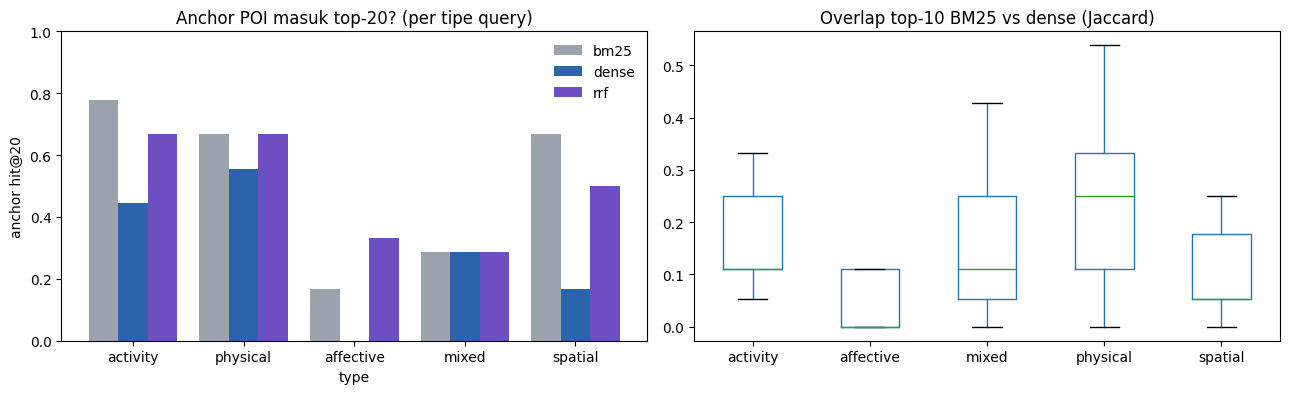

In [13]:
# Sanity check setelah rerun: apakah POI "anchor" muncul di top-20 tiap metode?
# anchor_hint = tebakan awal, BUKAN ground truth. Dipakai buat nemu query yang perlu direvisi.
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUNS = f"{WORK}/out_dense/runs_text.csv"   # berisi bm25, dense, rrf sekaligus
q = pd.read_csv(f"{WORK}/queries.csv")
runs = pd.read_csv(RUNS)
METHODS = [m for m in ["bm25", "dense", "rrf"] if m in set(runs["method"])]


def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def anchors(h):
    if not isinstance(h, str):
        return []
    out = []
    for a in h.split(";"):
        a = a.replace("(cek)", "").replace(" area", "").strip()
        if a:
            out.append(norm(a))
    return out


A = {r.id: anchors(r.anchor_hint) for r in q.itertuples()}
rows = []
for qid, g in runs.groupby("query_id"):
    for m in METHODS:
        gm = g[g["method"] == m].sort_values("rank")
        names = gm["name"].map(norm).tolist()
        best = None
        for rank, n in enumerate(names, 1):
            if any(a in n or n in a for a in A.get(qid, [])):
                best = rank
                break
        rows.append({"query_id": qid, "method": m, "anchor_rank": best})
hit = pd.DataFrame(rows).merge(q[["id", "type", "state", "text"]], left_on="query_id", right_on="id")
hit["has_anchor"] = hit["query_id"].map(lambda x: len(A.get(x, [])) > 0)
ha = hit[hit["has_anchor"]].copy()
ha["hit@10"] = ha["anchor_rank"].fillna(99) <= 10
ha["hit@20"] = ha["anchor_rank"].notna()

# overlap top-10 antar metode (seberapa beda kandidatnya -> ukuran pool annotasi)
top10 = runs[runs["rank"] <= 10].groupby(["query_id", "method"])["business_id"].apply(set).unstack()
ov = pd.DataFrame({
    "jaccard_bm25_dense": [len(a & b) / len(a | b) for a, b in zip(top10["bm25"], top10["dense"])]
    if {"bm25", "dense"} <= set(top10.columns) else np.nan,
    "pool_size_top10": top10.apply(lambda r: len(set().union(*[s for s in r if isinstance(s, set)])), axis=1),
}, index=top10.index)

print("=== Anchor hit rate (hanya query yang punya anchor) ===")
print(ha.groupby("method")[["hit@10", "hit@20"]].mean().round(2).loc[METHODS])
print("\n=== Hit@20 per tipe query ===")
print(ha.pivot_table(index="type", columns="method", values="hit@20", aggfunc="mean").round(2)[METHODS])
print(f"\nRata-rata Jaccard top-10 BM25 vs dense: {ov['jaccard_bm25_dense'].mean():.2f}")
print(f"Total pasangan di pool top-10: {int(ov['pool_size_top10'].sum())} "
      f"(rata-rata {ov['pool_size_top10'].mean():.1f} per query)")

miss = ha.groupby(["query_id", "text"])["hit@20"].any()
miss = miss[~miss].reset_index()
print(f"\n=== {len(miss)} query yang anchor-nya tidak masuk top-20 di metode mana pun (cek ulang) ===")
print(miss[["query_id", "text"]].to_string(index=False))

# ---- plot
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
pv = ha.pivot_table(index="type", columns="method", values="hit@20", aggfunc="mean")[METHODS]
pv = pv.reindex(["activity", "physical", "affective", "mixed", "spatial"]).dropna(how="all")
pv.plot.bar(ax=ax[0], rot=0, width=0.8, color=["#9CA3AF", "#2C64AB", "#6D4FC2"][:len(METHODS)])
ax[0].set_ylim(0, 1)
ax[0].set_ylabel("anchor hit@20")
ax[0].set_title("Anchor POI masuk top-20? (per tipe query)")
ax[0].legend(frameon=False)
ov2 = ov.join(q.set_index("id")["type"])
ov2.boxplot(column="jaccard_bm25_dense", by="type", ax=ax[1], grid=False)
ax[1].set_title("Overlap top-10 BM25 vs dense (Jaccard)")
ax[1].set_xlabel("")
fig.suptitle("")
plt.tight_layout()
plt.savefig(f"{WORK}/sanity_baseline.png", dpi=150)
plt.show()
hit.to_csv(f"{WORK}/anchor_hits.csv", index=False)


In [14]:
import shutil

# Arguments: (output_filename, format, source_dir)
# Do not include the '.zip' extension in the output name; it is added automatically.
shutil.make_archive("baseline_result_dense", "zip", "/kaggle/working/poi-retrieval/out_dense")

'/kaggle/working/poi-retrieval/baseline_result_dense.zip'